In [10]:
import emcee
import numpy as np
import matplotlib.pyplot as plt
import copy
import importlib
import os
from astropy.io import fits
import scipy.constants as sc

In [11]:

np.random.seed(100)

In [105]:
datapath          = 'SigOriData/'
obs_measurement_set            = f'{datapath}SO1152_12CO.ms.contsub_lsrk_avg'
mdict_name_prefix = f"{datapath}SO1152_12CO"
outname           = f'{datapath}SO1152_init_walker'
rest_freq_Hz      = 345.7959899e9
rest_freq_GH_str  = '345.7959899GHz'
dist              = 391.3        # pc
vra               = [7e3, 1.8e4] # velocity range for fitdata [m/s]
Nwalk             = 1 # number of walkers for MCMC (1 for test)

In [111]:

priors = importlib.import_module('priors_CSALT0_SDJ')
Ndim = len(priors.pri_pars)
p0 = np.empty((Nwalk, Ndim))

name_to_idx = {name: i for i, name in enumerate(priors.priors_dict)} 
        
for ix in range(Ndim):
    if priors.pri_types[ix] == "linewidth":
                temp_idx = name_to_idx["Tb_10"] # what id is Tb_10, in case not ix=9

                Tmin, Tmax = priors.pri_pars[temp_idx]
            
                thermal_width_min = np.sqrt(
                    2 * sc.k * Tmin /
                    (28 * (sc.m_p + sc.m_e))
                    )
                thermal_width_max = np.sqrt(
                    2 * sc.k * Tmax /
                    (28 * (sc.m_p + sc.m_e))
                    )

                #sample randomly from deltav_min to deltav_max 
                p0[:, ix] = np.random.uniform(
                    low=thermal_width_min,
                    high=thermal_width_max,
                    size=Nwalk)
                
#            if ix == 9:
#                p0[:,ix] = np.sqrt(2 * sc.k * p0[:,6] / (28 * (sc.m_p+sc.m_e)))
    else:
                _ = [str(priors.pri_pars[ix][ip])+', '
                     for ip in range(len(priors.pri_pars[ix]))]
                cmd = 'np.random.'+priors.pri_types[ix]+ \
                      '('+"".join(_)+str(Nwalk)+')'
                try: 
                    p0[:,ix] = eval(cmd)
                except AttributeError: 
                    pass 

theta = p0[0]


# Print the init parameters clearly
param_names = list(priors.priors_dict.keys())

param_names = list(priors.priors_dict.keys())
print("--- First walker initial parameters ---")
for name, val in zip(param_names, theta):
    print(f"  {name:>12s} = {val:.4f}")

--- First walker initial parameters ---
           inc = 65.6622
            PA = 325.5104
         mstar = 0.5305
          z_10 = 3.2055
           z_q = 1.1674
         Tb_10 = 56.0222
          Tb_q = -0.2837
        Tmax_b = 79.0618
         z_tap = 116.5888
         z_exp = 3.2465
     logtau_10 = 0.6180
         tau_q = -0.5113
       tau_tap = 103.4342
       tau_exp = 49.1204
          vlsr = 12492.7188
            dx = -0.0579
            dy = -0.1199


In [121]:
pars = theta

In [113]:
inc = 65.6622
PA = 325.5104
mstar = 0.5305
z_10 = 3.2055
z_q = 1.1674
Tb_10 = 56.0222
Tb_q = -0.2837
Tmax_b = 79.0618
z_tap = 116.5888
z_exp = 3.2465
logtau_10 = 0.6180
tau_q = -0.5113
tau_tap = 103.4342
tau_exp = 49.1204
vlsr = 12492.7188
dx = -0.0579
dy = -0.1199

In [ ]:
def tapered_powerlaw(r, y_0, r_0, y_q, y_tap, y_exp):
    """Exponentially tapered power law."""
    return y_0 * (r / r_0)**y_q * np.exp(-(r / y_tap)**y_exp)

#def Tgas(r):
#    """Peak brightness profile in [K]."""
#    return tapered_powerlaw(r, Tb_10, 10., Tb_q, Tb_tap, Tb_exp)

def tau_old(r):
    """Optical depth profile."""
    return tapered_powerlaw(r, 10**logtau_10, 10., tau_q, r_l, np.inf)

def z_f_old(r):
    """Emission surface of the front side of the disk."""
    return tapered_powerlaw(r, z_10, 10., z_q, np.inf, np.inf) # changed from 1'' to 10''

def z_b_old(r):
    """Emission surface for the back side of the disk."""
    return -z_f_old(r)

def dV(r):
    """Doppler linewidth profile in [m/s]."""
    return tapered_powerlaw(r, dV_10, 10., dV_q, dV_tap, dV_exp)



#### NEW MODEL 


def z_f(r):
    """Emission surface of the front side of the disk."""
    return tapered_powerlaw(r, z_10, 10., z_q, z_tap, z_exp) # changed from 1'' to 10''

def z_b(r):
    """Emission surface for the back side of the disk."""
    return -z_f(r)


def Tgas_Zallo(r): 
    return Tb_10 * (r / 10) ** Tb_q


def dV_Zallo(r): 
    mu=28.0
    T = Tgas_Zallo(r)
    return np.sqrt(2.0 * sc.k * T / (mu * (sc.m_p + sc.m_e)))

def tau(r):
    """Optical depth profile."""
    return tapered_powerlaw(r, 10**logtau_10, 10., tau_q, tau_tap, tau_exp)


#dV_q = 0.5 * Tb_q
#z_tap, Tb_tap, dV_tap, tau_tap = np.inf, r_l, r_l, r_l
#z_exp, Tb_exp, dV_exp, tau_exp = np.inf, np.inf, np.inf, np.inf

/var/folders/cz/0k5dzksx1szdtp750kwzgszm0000gp/T/ipykernel_65440/1520580006.py:3: RuntimeWarning: divide by zero encountered in power
  return y_0 * (r / r_0)**y_q * np.exp(-(r / y_tap)**y_exp)
/var/folders/cz/0k5dzksx1szdtp750kwzgszm0000gp/T/ipykernel_65440/1520580006.py:19: RuntimeWarning: divide by zero encountered in power
  return Tb_10 * (r / 10) ** Tb_q


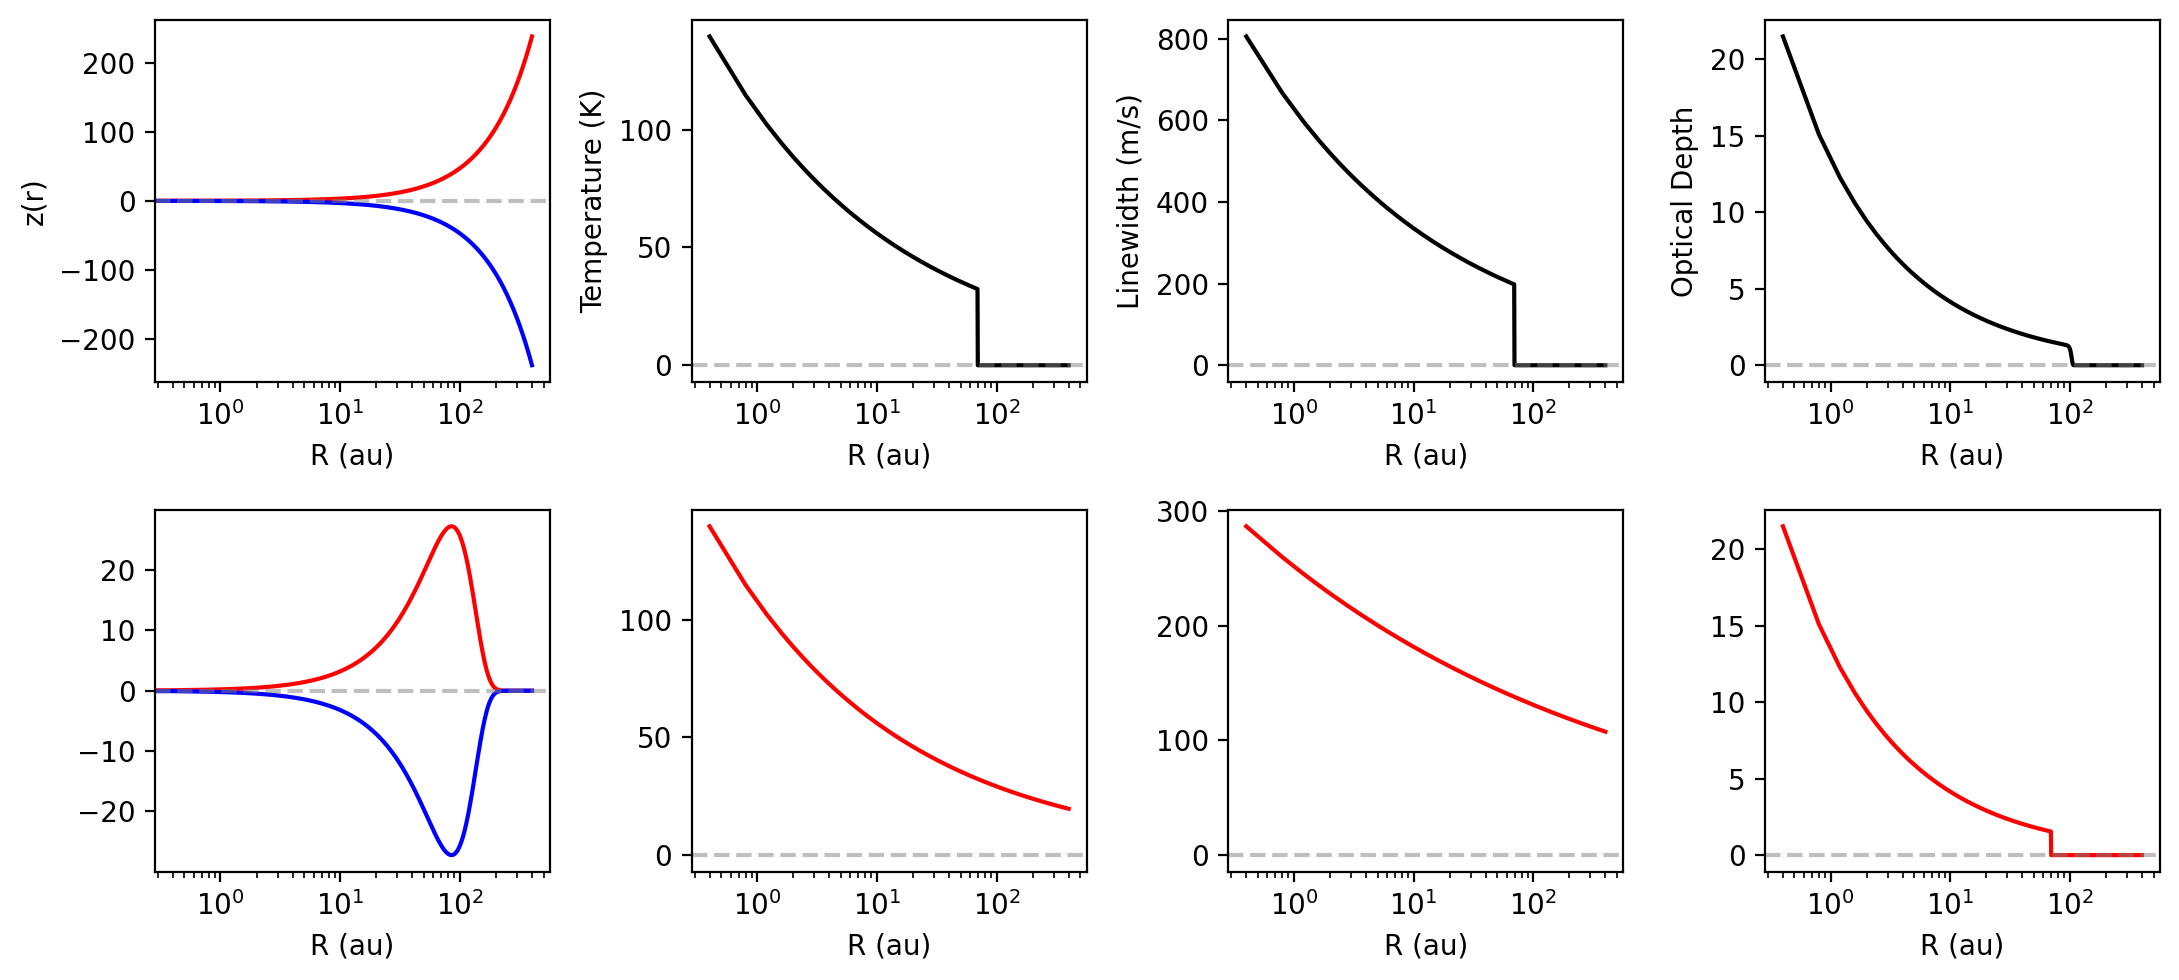

In [122]:
r = np.linspace(0, 400, 1000)  # radius in au

fig, axs = plt.subplots(2, 4, figsize=(11, 5), dpi=200)
axs = axs.flatten()

# --- Vertical structure ---
axs[0].plot(r, z_f_old(r), color="red", label="Old")
axs[0].plot(r, z_b_old(r), color="blue")

axs[4].plot(r, z_f(r), color="red", label="New")
axs[4].plot(r, z_b(r), color="blue")


# --- Temperature ---
axs[1].plot(r, Tgas(r), color="black")
axs[5].plot(r, Tgas_Zallo(r), color="red")


# --- Linewidth ---
axs[2].plot(r, dV(r), color="black")
axs[6].plot(r, dV_Zallo(r), color="red")


# --- Optical depth ---
axs[3].plot(r, tau(r), color="black")
axs[7].plot(r, tau_old(r), color="red")


# --- Formatting ---
for ax in axs:
    ax.set_xscale("log")
    ax.set_xlabel("R (au)")
    ax.axhline(0, color="gray", alpha=0.5, linestyle="--")

# Y-axis labels
axs[0].set_ylabel("z(r)")
axs[1].set_ylabel("Temperature (K)")
axs[2].set_ylabel("Linewidth (m/s)")
axs[3].set_ylabel("Optical Depth")

plt.tight_layout()
plt.show()